# 02 — Eksplorasi Data Olist (Exploratory Data Analysis)

## Tujuan Analisis

Tahap eksplorasi data bertujuan untuk memahami karakteristik dataset Olist, mengidentifikasi pola dan tren bisnis, serta menemukan informasi yang relevan untuk menjawab tiga pertanyaan bisnis utama dalam proyek ini.

## Ruang Lingkup Analisis

Analisis difokuskan pada tiga area utama:

1. **Penjualan dan Kategori Produk:** Mengidentifikasi tren penjualan, perkembangan pendapatan, dan kategori produk yang memiliki kontribusi terbesar.
2. **Keterlambatan Pengiriman dan Ulasan:** Menganalisis performa pengiriman, tingkat keterlambatan, serta hubungannya dengan kepuasan pelanggan.
3. **Pembayaran:** Mengevaluasi metode pembayaran, nilai transaksi, dan pola pembayaran pelanggan.

## Sumber Data

Seluruh analisis menggunakan enam dataset hasil pembersihan dari Notebook 01 yang tersimpan pada folder `Dataset/Processed/Cleaned/`.

## Prinsip Analisis

- Menggunakan dataset hasil pembersihan tanpa mengubah data sumber.
- Memeriksa distribusi dan karakteristik setiap variabel.
- Menggunakan visualisasi untuk mengidentifikasi pola dan tren.
- Mendokumentasikan temuan berdasarkan hasil perhitungan.
- Menghindari kesimpulan yang tidak didukung oleh data.


In [1]:

from pathlib import Path

# Menentukan lokasi folder dataset hasil pembersihan
CLEANED_DIR = (
    Path.cwd().parent
    / "Dataset"
    / "Processed"
    / "Cleaned"
)

# Memeriksa lokasi dan keberadaan folder
print("Lokasi kerja notebook:", Path.cwd())
print("Lokasi folder dataset:", CLEANED_DIR.resolve())
print("Folder ditemukan:", CLEANED_DIR.exists())

# Memeriksa file CSV di dalam folder
if CLEANED_DIR.exists():
    print("\nDaftar file CSV:")
    for file in sorted(CLEANED_DIR.glob("*.csv")):
        print("-", file.name)
else:
    print("\nFolder dataset belum ditemukan.")


Lokasi kerja notebook: /mnt/c/Users/ASUS/Github/Mini Project Olist/notebook
Lokasi folder dataset: /mnt/c/Users/ASUS/Github/Mini Project Olist/Dataset/Processed/Cleaned
Folder ditemukan: True

Daftar file CSV:
- category_translation_python_cleaned.csv
- date_conversion_report.csv
- duplicate_check_report.csv
- missing_values_report.csv
- numeric_conversion_report.csv
- order_items_python_cleaned.csv
- orders_python_cleaned.csv
- payments_python_cleaned.csv
- products_python_cleaned.csv
- reviews_python_cleaned.csv


In [2]:
# 3. MEMBACA DATASET HASIL PEMBERSIHAN NOTEBOOK 01


# IMPORT LIBRARY UTAMA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display


# Menentukan lokasi folder dataset hasil pembersihan
CLEANED_DIR = (
    Path.cwd().parent
    / "Dataset"
    / "Processed"
    / "Cleaned"
).resolve()

# Memeriksa lokasi folder
print("Lokasi folder dataset:", CLEANED_DIR)
print("Folder ditemukan:", CLEANED_DIR.exists())

# Nama seluruh dataset yang akan digunakan
FILE_NAMES = {
    "orders": "orders_python_cleaned.csv",
    "order_items": "order_items_python_cleaned.csv",
    "products": "products_python_cleaned.csv",
    "category_translation": "category_translation_python_cleaned.csv",
    "payments": "payments_python_cleaned.csv",
    "reviews": "reviews_python_cleaned.csv"
}

# Memastikan folder tersedia
if not CLEANED_DIR.exists():
    raise FileNotFoundError(
        f"Folder dataset tidak ditemukan: {CLEANED_DIR}"
    )

# Memastikan seluruh file dataset tersedia
missing_files = [
    filename
    for filename in FILE_NAMES.values()
    if not (CLEANED_DIR / filename).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"File dataset tidak ditemukan: {missing_files}"
    )

# Membaca seluruh dataset
eda_data = {}

for table_name, filename in FILE_NAMES.items():

    file_path = CLEANED_DIR / filename

    eda_data[table_name] = pd.read_csv(
        file_path,
        encoding="utf-8-sig",
        low_memory=False
    )

# Menampilkan konfirmasi pembacaan dataset
print("\nSeluruh dataset berhasil dibaca!")

# Menampilkan ringkasan dataset
print("\nRINGKASAN DATASET")
print("=" * 55)

for table_name, df in eda_data.items():

    print(f"\nDataset: {table_name}")
    print(f"Jumlah baris  : {df.shape[0]:,}")
    print(f"Jumlah kolom  : {df.shape[1]:,}")

print("\nSemua dataset siap digunakan untuk analisis EDA.")


Lokasi folder dataset: /mnt/c/Users/ASUS/Github/Mini Project Olist/Dataset/Processed/Cleaned
Folder ditemukan: True

Seluruh dataset berhasil dibaca!

RINGKASAN DATASET

Dataset: orders
Jumlah baris  : 99,441
Jumlah kolom  : 15

Dataset: order_items
Jumlah baris  : 112,650
Jumlah kolom  : 7

Dataset: products
Jumlah baris  : 32,951
Jumlah kolom  : 9

Dataset: category_translation
Jumlah baris  : 71
Jumlah kolom  : 2

Dataset: payments
Jumlah baris  : 103,886
Jumlah kolom  : 5

Dataset: reviews
Jumlah baris  : 99,224
Jumlah kolom  : 7

Semua dataset siap digunakan untuk analisis EDA.


In [3]:

# 4. Konversi kolom tanggal untuk analisis EDA

DATE_COLUMNS = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "order_items": [
        "shipping_limit_date"
    ],
    "reviews": [
        "review_creation_date",
        "review_answer_timestamp"
    ]
}

for table_name, columns in DATE_COLUMNS.items():
    for column in columns:
        if column in eda_data[table_name].columns:
            eda_data[table_name][column] = pd.to_datetime(
                eda_data[table_name][column],
                errors="coerce"
            )

print("Konversi kolom tanggal selesai.")


Konversi kolom tanggal selesai.


In [4]:

# 5. Ringkasan struktur dataset

dataset_summary = pd.DataFrame([
    {
        "table": table_name,
        "rows": len(dataframe),
        "columns": len(dataframe.columns),
        "memory_mb": round(
            dataframe.memory_usage(deep=True).sum() / (1024 ** 2), 2
        )
    }
    for table_name, dataframe in eda_data.items()
])

display(dataset_summary)

print("Total dataset:", len(eda_data))
print(
    "Total seluruh baris:",
    dataset_summary["rows"].sum()
)


,table,rows,columns,memory_mb
0,orders,99441,15,38.34
1,order_items,112650,7,29.54
2,products,32951,9,6.30
3,category_translation,71,2,0.01
4,payments,103886,5,16.23
5,reviews,99224,7,27.77


Total dataset: 6
Total seluruh baris: 448223


## 6. Analisis Penjualan dan Kategori Produk

Analisis ini bertujuan untuk memahami performa penjualan Olist berdasarkan perkembangan transaksi, pendapatan merchandise, biaya pengiriman, dan kontribusi kategori produk.

Analisis menggunakan pesanan dengan status `delivered`. Pendapatan merchandise dihitung berdasarkan kolom `price`, sedangkan biaya pengiriman dianalisis secara terpisah menggunakan kolom `freight_value`.

Tabel yang digunakan:
- orders
- order_items
- products
- category_translation


In [5]:

# 6.2 Membuat dataset analisis penjualan

# Mengambil salinan dataset
orders_sales = eda_data["orders"].copy()
items_sales = eda_data["order_items"].copy()
products_sales = eda_data["products"].copy()
category_sales = eda_data["category_translation"].copy()

# Memeriksa kolom yang dibutuhkan
required_columns = {
    "orders": [
        "order_id",
        "order_status",
        "order_purchase_timestamp"
    ],
    "order_items": [
        "order_id",
        "product_id",
        "price",
        "freight_value"
    ],
    "products": [
        "product_id",
        "product_category_name"
    ],
    "category_translation": [
        "product_category_name",
        "product_category_name_english"
    ]
}

for table_name, required in required_columns.items():
    missing = [
        column for column in required
        if column not in eda_data[table_name].columns
    ]

    if missing:
        raise ValueError(
            f"Kolom tidak ditemukan pada {table_name}: {missing}"
        )

# Memastikan tipe data sesuai
orders_sales["order_purchase_timestamp"] = pd.to_datetime(
    orders_sales["order_purchase_timestamp"],
    errors="coerce"
)

items_sales["price"] = pd.to_numeric(
    items_sales["price"], errors="coerce"
)

items_sales["freight_value"] = pd.to_numeric(
    items_sales["freight_value"], errors="coerce"
)

# Mengambil pesanan delivered dengan tanggal pembelian valid
orders_delivered = orders_sales[
    (orders_sales["order_status"] == "delivered")
    & (orders_sales["order_purchase_timestamp"].notna())
].copy()

# Menggabungkan pesanan dengan detail produk
analysis_sales = orders_delivered[
    ["order_id", "order_purchase_timestamp"]
].merge(
    items_sales,
    on="order_id",
    how="inner",
    validate="one_to_many"
)

# Menggabungkan informasi kategori produk
analysis_sales = analysis_sales.merge(
    products_sales[
        ["product_id", "product_category_name"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Menggabungkan terjemahan kategori
analysis_sales = analysis_sales.merge(
    category_sales,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

# Menentukan nama kategori untuk analisis
analysis_sales["category"] = (
    analysis_sales["product_category_name_english"]
    .fillna(analysis_sales["product_category_name"])
    .fillna("Tidak diketahui")
)

# Membuat kolom bulan pembelian
analysis_sales["purchase_month"] = (
    analysis_sales["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

# Ringkasan hasil penggabungan
print("DATASET ANALISIS PENJUALAN")
print("=" * 45)
print("Jumlah baris item:", len(analysis_sales))
print("Jumlah pesanan unik:", analysis_sales["order_id"].nunique())
print("Jumlah produk unik:", analysis_sales["product_id"].nunique())
print("Jumlah kategori:", analysis_sales["category"].nunique())
print("Price kosong:", analysis_sales["price"].isna().sum())
print("Kategori tidak diketahui:",
      analysis_sales["category"].eq("Tidak diketahui").sum())

display(analysis_sales.head(10))


DATASET ANALISIS PENJUALAN
Jumlah baris item: 110197
Jumlah pesanan unik: 96478
Jumlah produk unik: 32216
Jumlah kategori: 74
Price kosong: 0
Kategori tidak diketahui: 1537


,order_id,order_purchase_timestamp,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english,category,purchase_month
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,housewares,housewares,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumaria,perfumery,perfumery,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,automotivo,auto,auto,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,pet_shop,pet_shop,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,papelaria,stationery,stationery,2018-02
5,a4591c265e18cb1dcee52889e2d8acc3,2017-07-09 21:57:05,1,060cb19345d90064d1015407193c233d,8581055ce74af1daba164fdbd55a40de,2017-07-13 22:10:13,147.90,27.36,automotivo,auto,auto,2017-07
6,6514b8ad8028c9f2cc2374ded245783f,2017-05-16 13:10:30,1,4520766ec412348b8d4caa5e8a18c464,16090f2ca825584b5a147ab24aa30c86,2017-05-22 13:22:11,59.99,15.17,automotivo,auto,auto,2017-05
7,76c6e866289321a7c93b82b54852dc33,2017-01-23 18:29:09,1,ac1789e492dcd698c5c10b97a671243a,63b9ae557efed31d1f7687917d248a8d,2017-01-27 18:29:09,19.90,16.05,moveis_decoracao,furniture_decor,furniture_decor,2017-01
8,e69bfb5eb88e0ed6a785585b27e16dbf,2017-07-29 11:55:02,1,9a78fb9862b10749a117f7fc3c31f051,7c67e1448b00f6e969d365cea6b010ab,2017-08-11 12:05:32,149.99,19.77,moveis_escritorio,office_furniture,office_furniture,2017-07
9,e6ce16cb79ec1d90b1da9085a6118aeb,2017-05-16 19:41:10,1,08574b074924071f4e201e151b152b4e,001cca7ae9ae17fb1caed9dfb1094831,2017-05-22 19:50:18,99.00,30.53,ferramentas_jardim,garden_tools,garden_tools,2017-05


In [6]:
# 6.3 Validasi hasil penggabungan dataset penjualan

# Mengambil seluruh item dari pesanan delivered
expected_items = items_sales[
    items_sales["order_id"].isin(
        orders_delivered["order_id"]
    )
].copy()

# Memeriksa jumlah baris sebelum dan sesudah JOIN
validation_sales = pd.DataFrame({
    "metric": [
        "Expected item rows",
        "Actual item rows after JOIN",
        "Unique order IDs",
        "Unique order-item combinations",
        "Duplicate order-item combinations",
        "Missing price",
        "Unknown category"
    ],
    "value": [
        len(expected_items),
        len(analysis_sales),
        analysis_sales["order_id"].nunique(),
        analysis_sales[
            ["order_id", "order_item_id"]
        ].drop_duplicates().shape[0],
        analysis_sales.duplicated(
            subset=["order_id", "order_item_id"]
        ).sum(),
        analysis_sales["price"].isna().sum(),
        analysis_sales["category"].eq("Tidak diketahui").sum()
    ]
})

display(validation_sales)

# Memastikan jumlah baris tidak berubah akibat JOIN
assert len(expected_items) == len(analysis_sales), (
    "Jumlah baris berubah setelah JOIN."
)

# Memastikan tidak ada kombinasi item yang terduplikasi
assert not analysis_sales.duplicated(
    subset=["order_id", "order_item_id"]
).any(), "Ditemukan duplikasi item setelah JOIN."

print("Validasi JOIN berhasil.")


,metric,value
0,Expected item rows,110197
1,Actual item rows after JOIN,110197
2,Unique order IDs,96478
3,Unique order-item combinations,110197
4,Duplicate order-item combinations,0
5,Missing price,0
6,Unknown category,1537


Validasi JOIN berhasil.


In [7]:
# 6.4 Ringkasan performa penjualan

# Membuat nilai transaksi pada tingkat item
analysis_sales["merchandise_value"] = analysis_sales["price"]

analysis_sales["freight_value_total"] = (
    analysis_sales["freight_value"]
)

analysis_sales["item_plus_freight"] = (
    analysis_sales["price"]
    + analysis_sales["freight_value"]
)

# Menghitung total indikator penjualan
total_orders = analysis_sales["order_id"].nunique()

total_items = len(analysis_sales)

total_products = analysis_sales["product_id"].nunique()

total_gmv = analysis_sales["merchandise_value"].sum()

total_freight = analysis_sales["freight_value_total"].sum()

total_item_freight = analysis_sales["item_plus_freight"].sum()

average_order_value = total_gmv / total_orders

# Membuat tabel ringkasan
sales_overview = pd.DataFrame({
    "metric": [
        "Total delivered orders",
        "Total item transactions",
        "Unique products sold",
        "Merchandise sales (GMV)",
        "Total freight value",
        "Merchandise + freight value",
        "Average Order Value (AOV)"
    ],
    "value": [
        total_orders,
        total_items,
        total_products,
        total_gmv,
        total_freight,
        total_item_freight,
        average_order_value
    ]
})

display(sales_overview)

print("Ringkasan penjualan berhasil dibuat.")


,metric,value
0,Total delivered orders,9.647800e+04
1,Total item transactions,1.101970e+05
2,Unique products sold,3.221600e+04
3,Merchandise sales (GMV),1.322150e+07
4,Total freight value,2.198276e+06
5,Merchandise + freight value,1.541977e+07
6,Average Order Value (AOV),1.370416e+02


Ringkasan penjualan berhasil dibuat.


In [8]:

# 6.5 Analisis tren penjualan bulanan

monthly_sales = (
    analysis_sales
    .groupby("purchase_month")
    .agg(
        total_orders=("order_id", "nunique"),
        total_items=("order_item_id", "size"),
        merchandise_sales=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
    .reset_index()
)

# Menghitung AOV setiap bulan
monthly_sales["AOV"] = (
    monthly_sales["merchandise_sales"]
    / monthly_sales["total_orders"]
)

# Mengurutkan berdasarkan bulan
monthly_sales = monthly_sales.sort_values(
    "purchase_month"
).reset_index(drop=True)

display(monthly_sales)

print("Jumlah periode bulan:", len(monthly_sales))
print("Analisis penjualan bulanan selesai.")


,purchase_month,total_orders,total_items,merchandise_sales,freight_value,AOV
0,2016-09,1,3,134.97,8.49,134.970000
1,2016-10,265,313,40325.11,6165.55,152.170226
2,2016-12,1,1,10.90,8.72,10.900000
3,2017-01,750,913,111798.36,15684.01,149.064480
4,2017-02,1653,1858,234223.40,37015.92,141.695947
5,2017-03,2546,2897,359198.85,55132.10,141.083602
6,2017-04,2303,2569,340669.68,50142.72,147.924307
7,2017-05,3546,4004,489338.25,77513.15,137.997250
8,2017-06,3135,3489,421923.37,68127.00,134.584807
9,2017-07,3872,4416,481604.52,84694.56,124.381333


Jumlah periode bulan: 23
Analisis penjualan bulanan selesai.


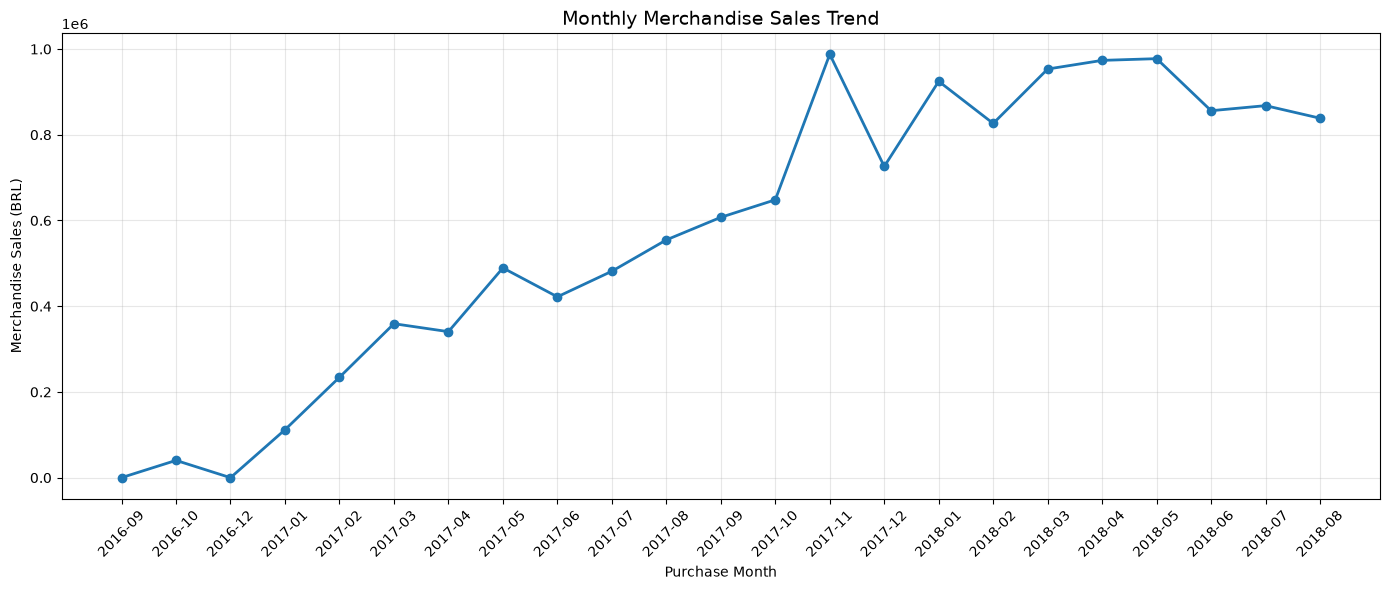

Visualisasi tren penjualan bulanan berhasil.


In [9]:

# 6.6 Visualisasi Tren Penjualan Bulanan

# Import library visualisasi
import matplotlib.pyplot as plt

# Membuat grafik tren penjualan bulanan
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["purchase_month"],
    monthly_sales["merchandise_sales"],
    marker="o",
    linewidth=2
)

# Judul dan label grafik
plt.title(
    "Monthly Merchandise Sales Trend",
    fontsize=14
)

plt.xlabel("Purchase Month")
plt.ylabel("Merchandise Sales (BRL)")

# Pengaturan tampilan
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

# Menampilkan grafik
plt.show()

print("Visualisasi tren penjualan bulanan berhasil.")


In [10]:

# 6.7 Analisis performa kategori produk

category_summary = (
    analysis_sales
    .groupby("category", dropna=False)
    .agg(
        total_orders=("order_id", "nunique"),
        total_items=("order_item_id", "count"),
        unique_products=("product_id", "nunique"),
        merchandise_sales=("price", "sum"),
        average_item_price=("price", "mean"),
        freight_value=("freight_value", "sum")
    )
    .reset_index()
)

# Menghitung kontribusi penjualan setiap kategori
category_summary["sales_contribution_pct"] = (
    category_summary["merchandise_sales"]
    / total_gmv * 100
)

# Mengurutkan kategori berdasarkan GMV tertinggi
category_summary = (
    category_summary
    .sort_values(
        "merchandise_sales",
        ascending=False
    )
    .reset_index(drop=True)
)

# Menampilkan 15 kategori teratas
display(category_summary.head(15))

print("Jumlah kategori:", len(category_summary))
print("Analisis kategori produk selesai.")


,category,total_orders,total_items,unique_products,merchandise_sales,average_item_price,freight_value,sales_contribution_pct
0,health_beauty,8647,9465,2397,1233131.72,130.283330,178957.81,9.326717
1,watches_gifts,5495,5859,1300,1166176.98,199.040276,98156.14,8.820309
2,bed_bath_table,9272,10953,2991,1023434.76,93.438762,201774.50,7.740687
3,sports_leisure,7530,8431,2822,954852.55,113.254958,163404.36,7.221969
4,computers_accessories,6530,7644,1600,888724.61,116.264339,143999.16,6.721815
5,furniture_decor,6307,8160,2593,711927.69,87.246040,168402.23,5.384622
6,housewares,5743,6795,2282,615628.69,90.600249,142763.56,4.656270
7,cool_stuff,3559,3718,770,610204.10,164.121598,81476.79,4.615242
8,auto,3810,4140,1853,578966.65,139.847017,90488.10,4.378979
9,toys,3804,4030,1373,471286.48,116.944536,75774.58,3.564547


Jumlah kategori: 74
Analisis kategori produk selesai.


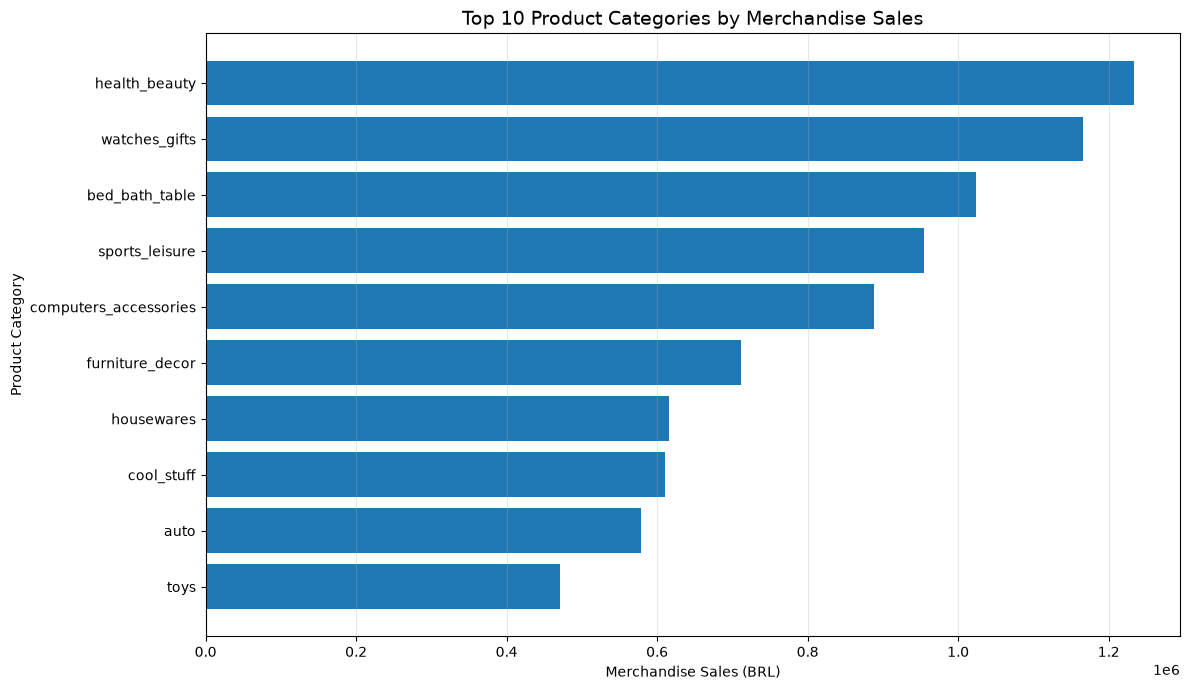

In [11]:

# 6.8 Visualisasi 10 kategori dengan penjualan tertinggi

top_10_categories = (
    category_summary
    .head(10)
    .sort_values("merchandise_sales")
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_categories["category"],
    top_10_categories["merchandise_sales"]
)

plt.title(
    "Top 10 Product Categories by Merchandise Sales",
    fontsize=14
)

plt.xlabel("Merchandise Sales (BRL)")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Analisis Keterlambatan Pengiriman dan Ulasan Pelanggan

Analisis ini bertujuan mengevaluasi performa pengiriman pesanan Olist, mengidentifikasi tingkat keterlambatan, serta memahami hubungan antara ketepatan waktu pengiriman dan penilaian pelanggan.


In [12]:

# 7.1 Ringkasan performa pengiriman

orders_delivery = eda_data["orders"].copy()

# Memastikan kolom tanggal memiliki format datetime
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_delivery[col] = pd.to_datetime(
        orders_delivery[col],
        errors="coerce"
    )

# Mengidentifikasi pesanan delivered
delivered_mask = (
    orders_delivery["order_status"] == "delivered"
)

# Mengambil kolom tanggal
purchase = orders_delivery["order_purchase_timestamp"]
carrier = orders_delivery["order_delivered_carrier_date"]
delivered = orders_delivery["order_delivered_customer_date"]
estimated = orders_delivery["order_estimated_delivery_date"]

# Mengidentifikasi anomali tanggal
carrier_before_purchase = (
    carrier.notna()
    & purchase.notna()
    & (carrier < purchase)
)

customer_before_carrier = (
    delivered.notna()
    & carrier.notna()
    & (delivered < carrier)
)

customer_before_purchase = (
    delivered.notna()
    & purchase.notna()
    & (delivered < purchase)
)

# Menentukan pesanan yang layak dianalisis
eligible_mask = (
    delivered_mask
    & orders_delivery["delivery_group"].notna()
    & orders_delivery["delivery_delay_days"].notna()
    & purchase.notna()
    & delivered.notna()
    & estimated.notna()
    & ~carrier_before_purchase
    & ~customer_before_carrier
    & ~customer_before_purchase
)

delivery_valid = orders_delivery.loc[eligible_mask].copy()

# Mengelompokkan pesanan
late_mask = delivery_valid["delivery_group"] == "Late"

ontime_mask = (
    delivery_valid["delivery_group"] == "On time / early"
)

# Menghitung jumlah pesanan
total_delivered = int(delivered_mask.sum())
total_eligible = len(delivery_valid)
total_late = int(late_mask.sum())
total_ontime = int(ontime_mask.sum())

total_excluded = int(
    (delivered_mask & ~eligible_mask).sum()
)

# Menghitung persentase keterlambatan
late_percentage = (
    total_late / total_eligible * 100
    if total_eligible > 0 else 0
)

# Menghitung rata-rata durasi pengiriman
average_delivery_days = (
    delivery_valid["delivery_duration_days"].mean()
)

# Menghitung rata-rata keterlambatan
average_late_days = (
    delivery_valid.loc[
        late_mask,
        "delivery_delay_days"
    ].mean()
)

# Membuat ringkasan
delivery_summary = pd.DataFrame({
    "metric": [
        "Total delivered orders",
        "Eligible delivered orders",
        "Late orders",
        "On time / early orders",
        "Excluded delivered orders",
        "Late percentage (%)",
        "Average delivery duration (days)",
        "Average delay among late orders (days)"
    ],
    "value": [
        total_delivered,
        total_eligible,
        total_late,
        total_ontime,
        total_excluded,
        round(late_percentage, 2),
        round(average_delivery_days, 2),
        round(average_late_days, 2)
    ]
})

display(delivery_summary)

print("Analisis performa pengiriman selesai.")


,metric,value
0,Total delivered orders,96478.00
1,Eligible delivered orders,96282.00
2,Late orders,6532.00
3,On time / early orders,89750.00
4,Excluded delivered orders,196.00
5,Late percentage (%),6.78
6,Average delivery duration (days),12.51
7,Average delay among late orders (days),10.62


Analisis performa pengiriman selesai.


In [13]:

# Audit tambahan: estimasi pengiriman sebelum pembelian

estimated_before_purchase = (
    delivered_mask
    & purchase.notna()
    & estimated.notna()
    & (estimated < purchase)
)

# Menghitung kasus yang masih masuk dalam kategori eligible
additional_cases = int(
    (eligible_mask & estimated_before_purchase).sum()
)

print(
    "Estimasi pengiriman sebelum pembelian "
    "yang masih masuk eligible:",
    additional_cases
)

# Menampilkan detail pesanan yang ditemukan
display(
    orders_delivery.loc[
        eligible_mask & estimated_before_purchase,
        [
            "order_id",
            "order_purchase_timestamp",
            "order_estimated_delivery_date",
            "order_delivered_customer_date",
            "delivery_delay_days",
            "delivery_group"
        ]
    ].head(20)
)


Estimasi pengiriman sebelum pembelian yang masih masuk eligible: 0


,order_id,order_purchase_timestamp,order_estimated_delivery_date,order_delivered_customer_date,delivery_delay_days,delivery_group


In [14]:

# AUDIT: Memeriksa seluruh penyebab perbedaan data

audit = orders_delivery.loc[delivered_mask].copy()

p = audit["order_purchase_timestamp"]
c = audit["order_delivered_carrier_date"]
d = audit["order_delivered_customer_date"]
e = audit["order_estimated_delivery_date"]

audit_conditions = {
    "Missing purchase date": p.isna(),

    "Missing carrier date": c.isna(),

    "Missing customer delivery date": d.isna(),

    "Missing estimated delivery date": e.isna(),

    "Carrier before purchase": (
        c.notna() & p.notna() & (c < p)
    ),

    "Customer before carrier": (
        d.notna() & c.notna() & (d < c)
    ),

    "Customer before purchase": (
        d.notna() & p.notna() & (d < p)
    ),

    "Estimated before purchase": (
        e.notna() & p.notna() & (e < p)
    ),

    "Delivery group missing": (
        audit["delivery_group"].isna()
    ),

    "Delivery delay missing": (
        audit["delivery_delay_days"].isna()
    )
}

audit_result = pd.DataFrame({
    "condition": list(audit_conditions.keys()),
    "total_cases": [
        int(condition.sum())
        for condition in audit_conditions.values()
    ],
    "still_eligible": [
        int(
            (condition & eligible_mask.loc[audit.index]).sum()
        )
        for condition in audit_conditions.values()
    ]
})

display(audit_result)

print("Audit pemeriksaan data selesai.")


,condition,total_cases,still_eligible
0,Missing purchase date,0,0
1,Missing carrier date,2,1
2,Missing customer delivery date,8,0
3,Missing estimated delivery date,0,0
4,Carrier before purchase,165,0
5,Customer before carrier,23,0
6,Customer before purchase,0,0
7,Estimated before purchase,0,0
8,Delivery group missing,31,0
9,Delivery delay missing,31,0


Audit pemeriksaan data selesai.


In [15]:

# AUDIT: Pemeriksaan durasi pengiriman tidak valid

duration = pd.to_numeric(
    orders_delivery["delivery_duration_days"],
    errors="coerce"
)

negative_duration = (
    delivered_mask & duration.lt(0)
)

missing_duration = (
    delivered_mask & duration.isna()
)

# Memeriksa jumlah kasus
print(
    "Durasi pengiriman negatif:",
    int(negative_duration.sum())
)

print(
    "Durasi pengiriman kosong:",
    int(missing_duration.sum())
)

print(
    "Durasi negatif yang masih masuk eligible:",
    int((eligible_mask & negative_duration).sum())
)

# Menampilkan detail pesanan
display(
    orders_delivery.loc[
        delivered_mask & (negative_duration | carrier.isna()),
        [
            "order_id",
            "order_purchase_timestamp",
            "order_delivered_carrier_date",
            "order_delivered_customer_date",
            "delivery_duration_days",
            "delivery_delay_days",
            "delivery_group"
        ]
    ].head(30)
)


Durasi pengiriman negatif: 0
Durasi pengiriman kosong: 31
Durasi negatif yang masih masuk eligible: 0


,order_id,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,delivery_duration_days,delivery_delay_days,delivery_group
73222,2aa91108853cecb43c84a5dc5b277475,2017-09-29 08:52:58,NaT,2017-11-20 19:44:47,52.0,6.0,Late
92643,2d858f451373b04fb5c984a1cc2defaf,2017-05-25 23:22:43,NaT,NaT,NaN,NaN,NaN


In [16]:

# AUDIT: Membandingkan perhitungan tanggal Python dan SQL

# Menghitung selisih berdasarkan tanggal kalender
sql_delay = (
    delivered.dt.normalize()
    - estimated.dt.normalize()
).dt.days

# Mengelompokkan berdasarkan logika SQL
sql_group = pd.Series(
    np.where(
        delivered.dt.normalize() > estimated.dt.normalize(),
        "Late",
        "On time / early"
    ),
    index=orders_delivery.index
)

# Menggunakan kriteria pesanan yang layak dianalisis
date_complete = (
    eligible_mask
    & delivered.notna()
    & estimated.notna()
)

# Mengambil hasil perhitungan Python
stored_delay = pd.to_numeric(
    orders_delivery["delivery_delay_days"],
    errors="coerce"
)

stored_group = orders_delivery["delivery_group"].astype("string")

# Membandingkan kedua hasil
delay_mismatch = (
    date_complete
    & stored_delay.ne(sql_delay)
)

group_mismatch = (
    date_complete
    & stored_group.fillna("<MISSING>").ne(sql_group)
)

# Ringkasan hasil perbandingan
comparison_result = pd.DataFrame({
    "metric": [
        "Python vs SQL delay mismatch",
        "Python vs SQL group mismatch",
        "Late based on Python",
        "Late based on SQL"
    ],
    "value": [
        int(delay_mismatch.sum()),
        int(group_mismatch.sum()),
        int((date_complete & stored_group.eq("Late")).sum()),
        int((date_complete & sql_group.eq("Late")).sum())
    ]
})

display(comparison_result)

# Menampilkan detail pesanan yang berbeda
comparison_detail = orders_delivery.loc[
    date_complete & (delay_mismatch | group_mismatch),
    [
        "order_id",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_delay_days",
        "delivery_group"
    ]
].copy()

comparison_detail["sql_delay_days"] = sql_delay.loc[
    comparison_detail.index
]

comparison_detail["sql_delivery_group"] = sql_group.loc[
    comparison_detail.index
]

display(comparison_detail.head(20))

print("Validasi perhitungan tanggal selesai.")


,metric,value
0,Python vs SQL delay mismatch,0
1,Python vs SQL group mismatch,0
2,Late based on Python,6532
3,Late based on SQL,6532


,order_id,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,delivery_group,sql_delay_days,sql_delivery_group


Validasi perhitungan tanggal selesai.


In [17]:
# Pemeriksaan jumlah data Python dan SQL

validation_counts = pd.DataFrame({
    "metric": [
        "Total delivered orders",
        "Eligible orders (Python)",
        "Rows used in comparison",
        "SQL delay available",
        "SQL group available",
        "Missing SQL delay in comparison",
        "Missing SQL group in comparison",
        "Late orders (Python)",
        "Late orders (SQL)"
    ],
    "value": [
        int(delivered_mask.sum()),
        int(eligible_mask.sum()),
        int(date_complete.sum()),
        int(sql_delay.notna().sum()),
        int(sql_group.notna().sum()),
        int((date_complete & sql_delay.isna()).sum()),
        int((date_complete & sql_group.isna()).sum()),
        int((date_complete & stored_group.eq("Late")).sum()),
        int((date_complete & sql_group.eq("Late")).sum())
    ]
})

display(validation_counts)

,metric,value
0,Total delivered orders,96478
1,Eligible orders (Python),96282
2,Rows used in comparison,96282
3,SQL delay available,96476
4,SQL group available,99441
5,Missing SQL delay in comparison,0
6,Missing SQL group in comparison,0
7,Late orders (Python),6532
8,Late orders (SQL),6532


In [18]:

# 7.2 Audit pesanan delivered yang tidak terklasifikasi

unclassified_delivery = orders_delivery.loc[
    delivered_mask & ~eligible_mask,
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_delay_days",
        "delivery_group"
    ]
].copy()

print(
    "Jumlah pesanan delivered tidak terklasifikasi:",
    len(unclassified_delivery)
)

display(unclassified_delivery.head(20))


Jumlah pesanan delivered tidak terklasifikasi: 196


,order_id,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,delivery_group
615,b9afddbdcfadc9a87b41a83271c3e888,2018-08-16 13:50:48,2018-08-16 13:27:00,2018-08-24 14:58:37,2018-09-04,-11.0,On time / early
1111,ad133696906f6a78826daa0911b7daec,2018-06-15 15:41:22,2018-06-15 14:52:00,2018-06-22 18:09:37,2018-07-18,-26.0,On time / early
1329,74e033208dc13a7b8127eb8e73d09b76,2018-05-02 10:48:44,2018-05-02 09:49:00,2018-05-07 23:06:36,2018-05-29,-22.0,On time / early
1372,a6b58794fd2ba533359a76c08df576e3,2018-05-14 15:18:23,2018-05-14 13:46:00,2018-05-19 19:33:32,2018-06-08,-20.0,On time / early
1864,5792e0b1c8c8a2bf53af468c9a422c88,2018-07-26 13:25:14,2018-07-26 12:42:00,2018-07-30 14:45:02,2018-08-09,-10.0,On time / early
2760,c3eb293fd154223498b6551a728203e8,2018-07-19 14:06:04,2018-07-19 13:49:00,2018-07-24 19:35:36,2018-08-06,-13.0,On time / early
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:44:07,2017-11-30 18:12:23,NaT,2017-12-18,NaN,NaN
3473,b0c2a7d04b165525254254a728c50a4e,2018-06-07 13:28:30,2018-06-07 13:22:00,2018-06-21 17:36:43,2018-07-04,-13.0,On time / early
3661,2033a4586b5bec3229ebc1675a8ae092,2018-06-12 10:10:25,2018-06-12 10:09:00,2018-06-19 14:08:27,2018-07-19,-30.0,On time / early
4114,08adcddad19d3acf37d1fa01cb9ded1e,2018-06-27 11:16:44,2018-06-27 10:57:00,2018-06-29 17:39:53,2018-07-18,-19.0,On time / early


In [19]:

# 7.3 Pemeriksaan penyebab pesanan tidak terklasifikasi

# Mengambil kolom tanggal dengan nama variabel khusus
unclassified_purchase = pd.to_datetime(
    unclassified_delivery["order_purchase_timestamp"],
    errors="coerce"
)

unclassified_carrier = pd.to_datetime(
    unclassified_delivery["order_delivered_carrier_date"],
    errors="coerce"
)

unclassified_delivered = pd.to_datetime(
    unclassified_delivery["order_delivered_customer_date"],
    errors="coerce"
)

unclassified_estimated = pd.to_datetime(
    unclassified_delivery["order_estimated_delivery_date"],
    errors="coerce"
)

# Mengidentifikasi setiap kondisi data
unclassified_audit_flags = pd.DataFrame({

    "tanggal_pembelian_kosong":
        unclassified_purchase.isna(),

    "tanggal_carrier_kosong":
        unclassified_carrier.isna(),

    "tanggal_diterima_kosong":
        unclassified_delivered.isna(),

    "tanggal_estimasi_kosong":
        unclassified_estimated.isna(),

    "carrier_sebelum_pembelian": (
        unclassified_carrier.notna()
        & unclassified_purchase.notna()
        & (unclassified_carrier < unclassified_purchase)
    ),

    "diterima_sebelum_carrier": (
        unclassified_delivered.notna()
        & unclassified_carrier.notna()
        & (unclassified_delivered < unclassified_carrier)
    ),

    "diterima_sebelum_pembelian": (
        unclassified_delivered.notna()
        & unclassified_purchase.notna()
        & (unclassified_delivered < unclassified_purchase)
    ),

    "estimasi_sebelum_pembelian": (
        unclassified_estimated.notna()
        & unclassified_purchase.notna()
        & (unclassified_estimated < unclassified_purchase)
    ),

    "delivery_delay_kosong": (
        pd.to_numeric(
            unclassified_delivery["delivery_delay_days"],
            errors="coerce"
        ).isna()
    ),

    "delivery_group_kosong": (
        unclassified_delivery["delivery_group"].isna()
    )

}, index=unclassified_delivery.index)


# Menghitung jumlah setiap kondisi
unclassified_audit_counts = (
    unclassified_audit_flags
    .sum()
    .astype(int)
    .rename("jumlah_pesanan")
    .to_frame()
)

print("=== RINGKASAN PENYEBAB PESANAN TIDAK TERKLASIFIKASI ===")

display(unclassified_audit_counts)


# Mengidentifikasi kombinasi kondisi setiap pesanan
unclassified_audit_flags["kombinasi_anomali"] = (
    unclassified_audit_flags.apply(
        lambda row: " + ".join(
            row.index[row].tolist()
        ) if row.any() else "Tidak ada anomali terdeteksi",
        axis=1
    )
)

print("=== DISTRIBUSI KOMBINASI KONDISI ===")

display(
    unclassified_audit_flags["kombinasi_anomali"]
    .value_counts()
    .rename_axis("kombinasi_anomali")
    .reset_index(name="jumlah_pesanan")
)

print("Audit penyebab pesanan tidak terklasifikasi selesai.")


=== RINGKASAN PENYEBAB PESANAN TIDAK TERKLASIFIKASI ===


,jumlah_pesanan
tanggal_pembelian_kosong,0
tanggal_carrier_kosong,1
tanggal_diterima_kosong,8
tanggal_estimasi_kosong,0
carrier_sebelum_pembelian,165
diterima_sebelum_carrier,23
diterima_sebelum_pembelian,0
estimasi_sebelum_pembelian,0
delivery_delay_kosong,31
delivery_group_kosong,31


=== DISTRIBUSI KOMBINASI KONDISI ===


,kombinasi_anomali,jumlah_pesanan
0,carrier_sebelum_pembelian,165
1,diterima_sebelum_carrier + delivery_delay_koso...,23
2,tanggal_diterima_kosong + delivery_delay_koson...,7
3,tanggal_carrier_kosong + tanggal_diterima_koso...,1


Audit penyebab pesanan tidak terklasifikasi selesai.



### 7.4 Hubungan Ketepatan Waktu Pengiriman dengan Ulasan Pelanggan

Analisis ini bertujuan mengetahui perbedaan penilaian pelanggan berdasarkan ketepatan waktu pengiriman. Perbandingan dilakukan menggunakan rata-rata skor ulasan untuk pesanan yang terlambat dan pesanan yang diterima tepat waktu atau lebih awal.


In [20]:

# 7.4 Analisis hubungan pengiriman dengan ulasan pelanggan

reviews_data = eda_data["reviews"].copy()

# Memastikan skor ulasan bertipe numerik
reviews_data["review_score"] = pd.to_numeric(
    reviews_data["review_score"],
    errors="coerce"
)

# Menggabungkan beberapa ulasan dalam satu pesanan
reviews_per_order = (
    reviews_data
    .dropna(subset=["order_id", "review_score"])
    .groupby("order_id")
    .agg(
        average_review_score=("review_score", "mean"),
        review_count=("review_score", "count")
    )
    .reset_index()
)

# Menggabungkan data pengiriman dengan ulasan
delivery_review_data = (
    delivery_valid[
        ["order_id", "delivery_group", "delivery_delay_days"]
    ]
    .merge(
        reviews_per_order,
        on="order_id",
        how="inner",
        validate="one_to_one"
    )
)

# Membandingkan skor ulasan berdasarkan kelompok pengiriman
review_delivery_summary = (
    delivery_review_data
    .groupby("delivery_group")
    .agg(
        orders_with_reviews=("order_id", "nunique"),
        average_review_score=("average_review_score", "mean"),
        median_review_score=("average_review_score", "median"),
        total_review_records=("review_count", "sum")
    )
    .reset_index()
)

review_delivery_summary[
    ["average_review_score", "median_review_score"]
] = review_delivery_summary[
    ["average_review_score", "median_review_score"]
].round(2)

display(review_delivery_summary)

print("Analisis hubungan pengiriman dan ulasan selesai.")


,delivery_group,orders_with_reviews,average_review_score,median_review_score,total_review_records
0,Late,6379,2.27,1.0,6407
1,On time / early,89258,4.29,5.0,89759


Analisis hubungan pengiriman dan ulasan selesai.



### 7.5 Visualisasi Hubungan Ketepatan Waktu Pengiriman dengan Ulasan Pelanggan

Grafik ini membandingkan rata-rata skor ulasan pelanggan antara pesanan yang terlambat dan pesanan yang diterima tepat waktu atau lebih awal.


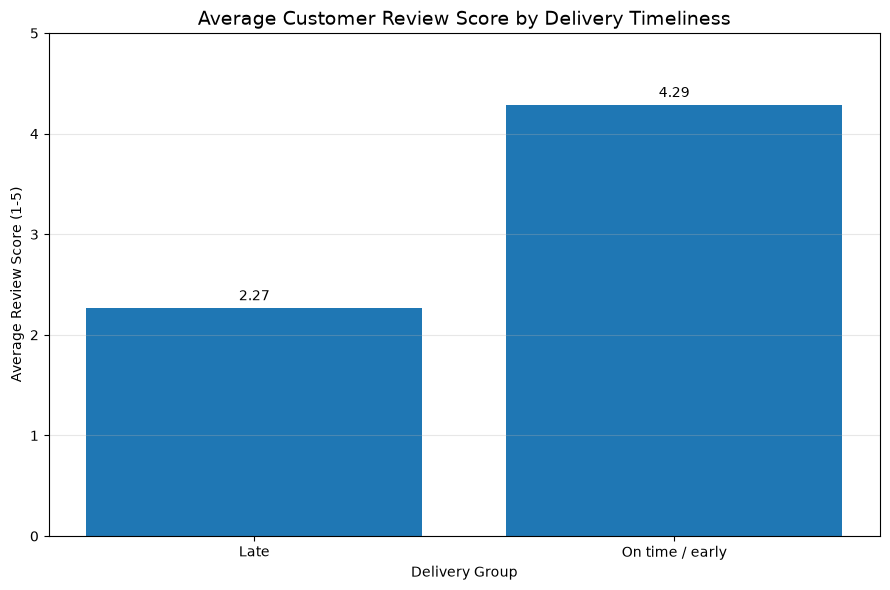

In [21]:

# 7.5 Visualisasi hubungan ketepatan waktu pengiriman dengan ulasan pelanggan

review_plot = review_delivery_summary.copy()

# Mengatur urutan kategori
delivery_order = ["Late", "On time / early"]

review_plot["delivery_group"] = pd.Categorical(
    review_plot["delivery_group"],
    categories=delivery_order,
    ordered=True
)

review_plot = review_plot.sort_values("delivery_group")

# Membuat grafik
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    review_plot["delivery_group"].astype(str),
    review_plot["average_review_score"]
)

ax.set_title(
    "Average Customer Review Score by Delivery Timeliness",
    fontsize=14
)

ax.set_xlabel("Delivery Group")
ax.set_ylabel("Average Review Score (1-5)")

ax.set_ylim(0, 5)
ax.set_yticks(range(0, 6))

ax.bar_label(bars, fmt="%.2f", padding=3)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



## 8. Analisis Metode dan Karakteristik Pembayaran

Analisis ini bertujuan mengidentifikasi metode pembayaran yang digunakan pelanggan, mengevaluasi nilai transaksi, serta memahami pola pembayaran berdasarkan jumlah cicilan dan karakteristik transaksi.


In [22]:

# 8.1 Persiapan dan ringkasan data pembayaran

payments_data = eda_data["payments"].copy()

# Menggunakan pesanan berstatus delivered
delivered_order_ids = orders_delivery.loc[
    orders_delivery["order_status"] == "delivered",
    "order_id"
]

payments_analysis = payments_data[
    payments_data["order_id"].isin(delivered_order_ids)
].copy()

# Memastikan kolom numerik
payments_analysis["payment_value"] = pd.to_numeric(
    payments_analysis["payment_value"],
    errors="coerce"
)

payments_analysis["payment_installments"] = pd.to_numeric(
    payments_analysis["payment_installments"],
    errors="coerce"
)

# Ringkasan transaksi pembayaran
payment_total = (
    payments_analysis
    .groupby("order_id")
    .agg(
        total_payment=("payment_value", "sum"),
        payment_records=("payment_sequential", "count")
    )
)

payment_overview = pd.DataFrame({
    "metric": [
        "Total delivered orders with payments",
        "Total payment records",
        "Total payment value (BRL)",
        "Average payment per order (BRL)",
        "Orders with multiple payment records"
    ],
    "value": [
        payment_total.shape[0],
        len(payments_analysis),
        round(payments_analysis["payment_value"].sum(), 2),
        round(payment_total["total_payment"].mean(), 2),
        int((payment_total["payment_records"] > 1).sum())
    ]
})

display(payment_overview)

# Ringkasan berdasarkan metode pembayaran
payment_method_summary = (
    payments_analysis
    .groupby("payment_type")
    .agg(
        total_orders=("order_id", "nunique"),
        payment_records=("order_id", "count"),
        total_payment_value=("payment_value", "sum"),
        average_payment_value=("payment_value", "mean"),
        average_installments=("payment_installments", "mean")
    )
    .reset_index()
    .sort_values("total_payment_value", ascending=False)
)

payment_method_summary[
    [
        "total_payment_value",
        "average_payment_value",
        "average_installments"
    ]
] = payment_method_summary[
    [
        "total_payment_value",
        "average_payment_value",
        "average_installments"
    ]
].round(2)

display(payment_method_summary)

print("Analisis awal pembayaran selesai.")


,metric,value
0,Total delivered orders with payments,96477.00
1,Total payment records,100756.00
2,Total payment value (BRL),15422461.77
3,Average payment per order (BRL),159.86
4,Orders with multiple payment records,2875.00


,payment_type,total_orders,payment_records,total_payment_value,average_payment_value,average_installments
1,credit_card,74304,74586,12101094.88,162.24,3.5
0,boleto,19191,19191,2769932.58,144.33,1.0
3,voucher,3679,5493,343013.19,62.45,1.0
2,debit_card,1485,1486,208421.12,140.26,1.0


Analisis awal pembayaran selesai.



### 8.2 Analisis Distribusi Jumlah Cicilan

Analisis ini bertujuan mengetahui pola penggunaan cicilan oleh pelanggan, khususnya pada metode pembayaran kartu kredit, serta melihat distribusi jumlah transaksi dan nilai pembayaran berdasarkan jumlah cicilan.


In [23]:

# 8.2 Distribusi jumlah cicilan kartu kredit

credit_card_payments = payments_analysis[
    payments_analysis["payment_type"] == "credit_card"
].copy()

installment_summary = (
    credit_card_payments
    .groupby("payment_installments")
    .agg(
        payment_records=("order_id", "count"),
        unique_orders=("order_id", "nunique"),
        total_payment_value=("payment_value", "sum"),
        average_payment_value=("payment_value", "mean")
    )
    .reset_index()
    .sort_values("payment_installments")
)

# Menghitung persentase catatan pembayaran
installment_summary["record_pct"] = (
    installment_summary["payment_records"]
    / installment_summary["payment_records"].sum()
    * 100
).round(2)

installment_summary[
    ["total_payment_value", "average_payment_value"]
] = installment_summary[
    ["total_payment_value", "average_payment_value"]
].round(2)

display(installment_summary)

print("Analisis distribusi cicilan selesai.")


,payment_installments,payment_records,unique_orders,total_payment_value,average_payment_value,record_pct
0,0,2,2,188.63,94.32,0.00
1,1,24759,24711,2366960.73,95.60,33.20
2,2,12075,12052,1528581.69,126.59,16.19
3,3,10164,10147,1443288.05,142.00,13.63
4,4,6891,6882,1127647.37,163.64,9.24
5,5,5095,5090,928837.73,182.30,6.83
6,6,3804,3800,793288.80,208.54,5.10
7,7,1563,1560,290643.18,185.95,2.10
8,8,4136,4122,1266801.58,306.29,5.55
9,9,618,618,122346.20,197.97,0.83


Analisis distribusi cicilan selesai.


In [24]:

# AUDIT: Konsistensi hasil analisis cicilan kartu kredit

print("=== AUDIT KONSISTENSI PEMBAYARAN ===")

print(
    "Total payment records:",
    len(credit_card_payments)
)

print(
    "Payment records hasil grouping:",
    installment_summary["payment_records"].sum()
)

print(
    "Total payment value:",
    round(credit_card_payments["payment_value"].sum(), 2)
)

print(
    "Total payment value hasil grouping:",
    round(installment_summary["total_payment_value"].sum(), 2)
)

print(
    "Total unique orders:",
    credit_card_payments["order_id"].nunique()
)

print("\nAudit pemeriksaan selesai.")


=== AUDIT KONSISTENSI PEMBAYARAN ===
Total payment records: 74586
Payment records hasil grouping: 74586
Total payment value: 12101094.88
Total payment value hasil grouping: 12101094.88
Total unique orders: 74304

Audit pemeriksaan selesai.


In [25]:

# Pemeriksaan pembayaran kartu kredit dengan cicilan 0

zero_installment = credit_card_payments.loc[
    credit_card_payments["payment_installments"] == 0,
    [
        "order_id",
        "payment_sequential",
        "payment_type",
        "payment_installments",
        "payment_value"
    ]
].copy()

print("Jumlah pembayaran dengan cicilan 0:", len(zero_installment))

display(zero_installment)


Jumlah pembayaran dengan cicilan 0: 2


,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


**Catatan Pemeriksaan Cicilan**

Ditemukan 2 catatan pembayaran kartu kredit dengan nilai `payment_installments` sebesar 0. Nilai tersebut tidak merepresentasikan jumlah cicilan yang valid. Kedua catatan tetap dipertahankan dalam dataset tanpa perubahan atau penghapusan dan diperlakukan sebagai anomali dalam interpretasi distribusi cicilan.

### 8.3 Proporsi Metode Pembayaran dan Distribusi Nilai Transaksi

Analisis ini bertujuan membandingkan proporsi penggunaan setiap metode pembayaran serta melihat kontribusi dan karakteristik nilai transaksi berdasarkan metode pembayaran yang digunakan pelanggan.


In [26]:

# 8.3 Proporsi metode pembayaran dan distribusi nilai transaksi

# Menghitung total data sebagai dasar persentase
total_payment_records = len(payments_analysis)
total_paid_orders = payments_analysis["order_id"].nunique()
total_payment_value = payments_analysis["payment_value"].sum()

# Ringkasan berdasarkan metode pembayaran
payment_distribution = (
    payments_analysis
    .groupby("payment_type", dropna=False)
    .agg(
        payment_records=("order_id", "size"),
        unique_orders=("order_id", "nunique"),
        total_payment_value=("payment_value", "sum"),
        average_payment_value=("payment_value", "mean"),
        median_payment_value=("payment_value", "median")
    )
    .reset_index()
)

# Menghitung proporsi catatan pembayaran
payment_distribution["record_pct"] = (
    payment_distribution["payment_records"]
    / total_payment_records * 100
)

# Menghitung persentase pesanan yang menggunakan metode tersebut
payment_distribution["order_pct"] = (
    payment_distribution["unique_orders"]
    / total_paid_orders * 100
)

# Menghitung kontribusi nilai pembayaran
payment_distribution["value_pct"] = (
    payment_distribution["total_payment_value"]
    / total_payment_value * 100
)

# Mengurutkan berdasarkan total nilai pembayaran
payment_distribution = (
    payment_distribution
    .sort_values("total_payment_value", ascending=False)
    .reset_index(drop=True)
)

# Pembulatan nilai
numeric_columns = [
    "total_payment_value",
    "average_payment_value",
    "median_payment_value",
    "record_pct",
    "order_pct",
    "value_pct"
]

payment_distribution[numeric_columns] = (
    payment_distribution[numeric_columns].round(2)
)

print("Total catatan pembayaran:", total_payment_records)
print("Total pesanan unik:", total_paid_orders)
print("Total nilai pembayaran (BRL):", round(total_payment_value, 2))

display(payment_distribution)

print("Analisis proporsi metode pembayaran selesai.")


Total catatan pembayaran: 100756
Total pesanan unik: 96477
Total nilai pembayaran (BRL): 15422461.77


,payment_type,payment_records,unique_orders,total_payment_value,average_payment_value,median_payment_value,record_pct,order_pct,value_pct
0,credit_card,74586,74304,12101094.88,162.24,106.84,74.03,77.02,78.46
1,boleto,19191,19191,2769932.58,144.33,93.78,19.05,19.89,17.96
2,voucher,5493,3679,343013.19,62.45,39.04,5.45,3.81,2.22
3,debit_card,1486,1485,208421.12,140.26,89.60,1.47,1.54,1.35


Analisis proporsi metode pembayaran selesai.


In [27]:

# AUDIT: Pemeriksaan penggunaan lebih dari satu metode pembayaran

# Menghitung jumlah metode pembayaran unik per pesanan
method_count_per_order = (
    payments_analysis
    .groupby("order_id")["payment_type"]
    .nunique()
)

# Mengidentifikasi pesanan dengan lebih dari satu metode
multi_method_orders = method_count_per_order[
    method_count_per_order > 1
]

# Menghitung total kemunculan pesanan pada seluruh metode
total_orders_by_method = int(
    payment_distribution["unique_orders"].sum()
)

total_unique_orders = int(
    payments_analysis["order_id"].nunique()
)

print("=== AUDIT METODE PEMBAYARAN ===")

print(
    "Total unique orders seluruh metode:",
    total_orders_by_method
)

print(
    "Total unique paid orders:",
    total_unique_orders
)

print(
    "Pesanan dengan lebih dari satu metode:",
    len(multi_method_orders)
)

print(
    "Tambahan kemunculan akibat metode ganda:",
    int((method_count_per_order - 1).clip(lower=0).sum())
)

print("\n=== DISTRIBUSI JUMLAH METODE PER PESANAN ===")

display(
    multi_method_orders.value_counts()
    .sort_index()
    .rename_axis("jumlah_metode")
    .reset_index(name="jumlah_pesanan")
)

print("Audit metode pembayaran selesai.")


=== AUDIT METODE PEMBAYARAN ===
Total unique orders seluruh metode: 98659
Total unique paid orders: 96477
Pesanan dengan lebih dari satu metode: 2182
Tambahan kemunculan akibat metode ganda: 2182

=== DISTRIBUSI JUMLAH METODE PER PESANAN ===


,jumlah_metode,jumlah_pesanan
0,2,2182


Audit metode pembayaran selesai.


In [28]:

# AUDIT ULANG: KONSISTENSI DISTRIBUSI METODE PEMBAYARAN

# Menghitung jumlah metode unik per pesanan
method_count_per_order = (
    payments_analysis
    .groupby("order_id")["payment_type"]
    .nunique()
)

# Menghitung total pesanan unik
total_unique_orders = int(
    payments_analysis["order_id"].nunique()
)

# Menghitung total kemunculan pesanan berdasarkan metode
total_method_assignments = int(
    method_count_per_order.sum()
)

# Menghitung pesanan dengan lebih dari satu metode
multi_method_orders = method_count_per_order[
    method_count_per_order > 1
]

# Menghitung tambahan kemunculan akibat metode ganda
extra_method_occurrences = int(
    (method_count_per_order - 1).clip(lower=0).sum()
)

# Menghitung ulang distribusi berdasarkan dataset
payment_distribution_check = (
    payments_analysis
    .groupby("payment_type")
    .agg(
        payment_records=("order_id", "size"),
        unique_orders=("order_id", "nunique")
    )
    .reset_index()
)

sum_unique_orders_by_method = int(
    payment_distribution_check["unique_orders"].sum()
)

print("=== AUDIT ULANG METODE PEMBAYARAN ===")

print("Total unique paid orders:", total_unique_orders)

print("Pesanan dengan lebih dari satu metode:",
      len(multi_method_orders))

print("Tambahan kemunculan metode:",
      extra_method_occurrences)

print("Total kemunculan pesanan berdasarkan metode:",
      total_method_assignments)

print("Total unique orders dari seluruh metode:",
      sum_unique_orders_by_method)

print("\n=== PEMERIKSAAN KONSISTENSI ===")

expected_total = (
    total_unique_orders + extra_method_occurrences
)

print("Hasil perhitungan yang diharapkan:", expected_total)

print("Selisih:",
      total_method_assignments - expected_total)

print("\n=== DISTRIBUSI METODE PER PESANAN ===")

display(
    method_count_per_order.value_counts()
    .sort_index()
    .rename_axis("jumlah_metode")
    .reset_index(name="jumlah_pesanan")
)

print("\nAudit ulang selesai.")


=== AUDIT ULANG METODE PEMBAYARAN ===
Total unique paid orders: 96477
Pesanan dengan lebih dari satu metode: 2182
Tambahan kemunculan metode: 2182
Total kemunculan pesanan berdasarkan metode: 98659
Total unique orders dari seluruh metode: 98659

=== PEMERIKSAAN KONSISTENSI ===
Hasil perhitungan yang diharapkan: 98659
Selisih: 0

=== DISTRIBUSI METODE PER PESANAN ===


,jumlah_metode,jumlah_pesanan
0,1,94295
1,2,2182



Audit ulang selesai.



### 8.4 Visualisasi Distribusi Metode Pembayaran

Visualisasi ini membandingkan proporsi jumlah catatan pembayaran dengan kontribusi nilai transaksi berdasarkan metode pembayaran yang digunakan pelanggan.


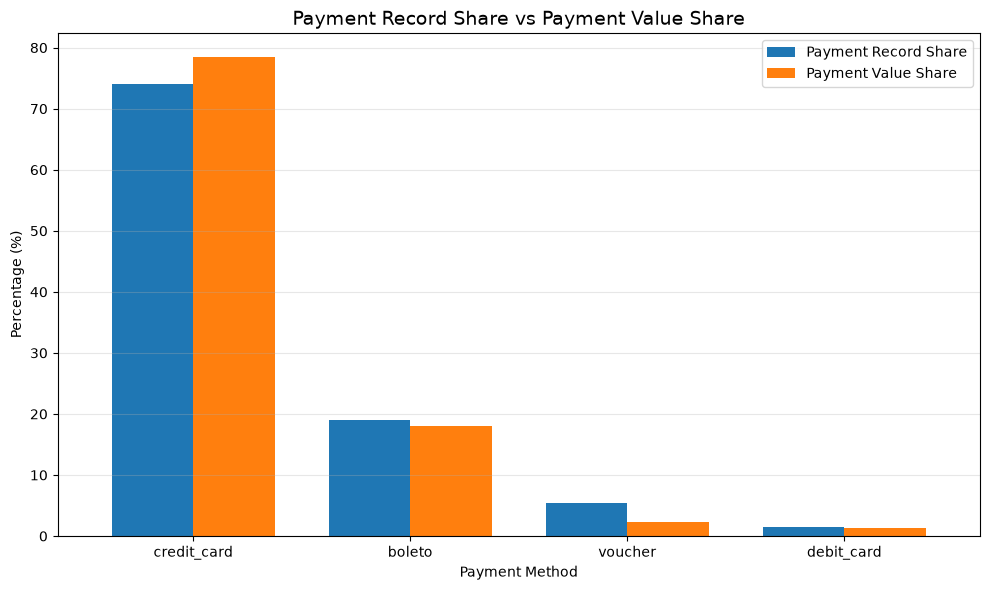

In [29]:

# 8.4 Visualisasi distribusi metode pembayaran

plot_payment = payment_distribution.set_index("payment_type")[
    ["record_pct", "value_pct"]
]

ax = plot_payment.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.set_title(
    "Payment Record Share vs Payment Value Share",
    fontsize=14
)

ax.set_xlabel("Payment Method")
ax.set_ylabel("Percentage (%)")

ax.legend([
    "Payment Record Share",
    "Payment Value Share"
])

ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



# 9. Ringkasan Temuan Exploratory Data Analysis

Tahap Exploratory Data Analysis (EDA) dilakukan untuk memahami karakteristik transaksi, performa penjualan, ketepatan pengiriman, ulasan pelanggan, serta metode pembayaran pada dataset Olist. Berdasarkan hasil eksplorasi, diperoleh beberapa temuan utama sebagai berikut.

### 9.1 Penjualan dan Kategori Produk

Analisis mencakup 110.197 baris item pesanan (*order items*) dari 96.478 pesanan unik, dengan 32.216 produk dan 74 kategori. Total merchandise sales (GMV) mencapai BRL 13.221.498,11 dengan Average Order Value (AOV) sebesar BRL 137,04. Kategori *health_beauty* menjadi kontributor penjualan terbesar, diikuti oleh *watches_gifts* dan *bed_bath_table*. Hasil ini menunjukkan bahwa kontribusi penjualan Olist terkonsentrasi pada beberapa kategori produk utama.

### 9.2 Kinerja Pengiriman dan Ulasan Pelanggan

Dari 96.282 pesanan delivered yang memenuhi kriteria analisis, terdapat 6.532 pesanan terlambat atau sebesar 6,78%, sedangkan 89.750 pesanan diterima tepat waktu atau lebih awal. Rata-rata durasi pengiriman adalah 12,51 hari. Analisis ulasan menunjukkan rata-rata skor 2,27 pada pesanan terlambat, sedangkan pesanan tepat waktu atau lebih awal memperoleh rata-rata skor 4,29. Temuan ini menunjukkan adanya hubungan antara ketepatan pengiriman dan kepuasan pelanggan.

### 9.3 Metode dan Karakteristik Pembayaran

Analisis mencakup 100.756 catatan pembayaran dengan total nilai pembayaran BRL 15.422.461,77. Kartu kredit menjadi metode pembayaran dengan kontribusi nilai transaksi terbesar, yaitu 78,46%. Selain itu, pembayaran kartu kredit memiliki variasi jumlah cicilan yang cukup beragam dan menjadi metode pembayaran dominan.

### 9.4 Catatan dan Keterbatasan Data

Beberapa kondisi data tetap dipertahankan untuk menjaga transparansi analisis, antara lain kategori produk yang tidak diketahui, pesanan delivered yang tidak memenuhi kriteria klasifikasi keterlambatan, serta dua catatan pembayaran kartu kredit dengan jumlah cicilan nol. Kondisi tersebut tidak dihapus secara otomatis dan perlu dipertimbangkan ketika menginterpretasikan hasil analisis.

### 9.5 Kesimpulan EDA

Hasil eksplorasi menunjukkan bahwa penjualan Olist didominasi oleh beberapa kategori produk utama, keterlambatan pengiriman berkaitan dengan rata-rata ulasan pelanggan yang lebih rendah, serta kartu kredit merupakan metode pembayaran dengan kontribusi nilai transaksi terbesar.

Temuan ini menjadi dasar untuk memahami performa bisnis Olist dan mendukung penyampaian insight melalui analisis data serta dashboard yang telah dibuat pada tahap Power BI.
